# Error analysis: content-only vs graph-only vs fusion (Minh)

Why does fusion win, and where does the graph hurt? Validation accounts only; the test set is not used.

- Three LR models with the `fusion_lr` settings (same as `baselines.ipynb` and `relations.ipynb`): content-only
  **P + C + T**, graph-only **G**, fusion **P + C + T + G**. Each model uses its own validation threshold.
- Two groups: **helped** (fusion right, content-only wrong: network signal helped) and **hurt** (fusion wrong,
  content-only right: network noise hurt).
- For each group: bots vs humans, degree per relation compared with the other validation accounts, and which relation
  moved the fusion score (sum of LR coefficient × standardized value over that relation's G columns).

In [1]:
# 1. Setup (Colab or local)
import os, sys
if not os.path.exists("mgtab.py"):
    if "google.colab" in sys.modules:
        if not os.path.exists("sna-content-moderation"):
            !git clone -q https://github.com/ThSonDev/sna-content-moderation.git
        %cd sna-content-moderation
        !pip install -q -r requirements.txt
        !python install_pyg.py
    else:
        %cd ..
sys.path.insert(0, os.getcwd())

/home/minhubuntu/projects/sna-content-moderation


In [2]:
# 2. Download MGTAB (31 MB) into data/MGTAB, only once
import urllib.request, zipfile
if not os.path.exists("data/MGTAB/features.pt"):
    os.makedirs("data", exist_ok=True)
    url = "https://drive.usercontent.google.com/download?id=1gbWNOoU1JB8RrTu2a5j9KMNVa9wX72Fe&export=download&confirm=t"
    urllib.request.urlretrieve(url, "data/MGTAB.zip")
    zipfile.ZipFile("data/MGTAB.zip").extractall("data")

In [3]:
# 3. Load data and the shared split (never make your own split)
import numpy as np
from mgtab import load, relations, split, best_threshold, evaluate, RELATIONS
X, y, stance, E, T, W = load()
rel = relations(E, T, len(y))   # {"follow": (src, dst), ...}
train, val, test = split(y)     # test stays locked until the final run
print(X.shape, {r: len(s) for r, (s, d) in rel.items()})

(10199, 788) {'follow': 425863, 'mention': 110868, 'reply': 22327, 'quote': 20901, 'url': 263800, 'hashtag': 300000}


## Models

In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler
from features import feature_groups

groups, g_names = feature_groups(X, rel)
Z = {k: StandardScaler().fit(v[train]).transform(v) for k, v in groups.items() if k != "T"}  # train statistics only
Z["T"] = groups["T"]                                                                       # T raw, as in the baselines
cols = {r: [j for j, c in enumerate(g_names) if c.startswith(r + "_")] for r in RELATIONS}

def fusion_lr(F):
    best = None
    for C in [0.01, 0.1, 1, 10]:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(F[train], y[train])
        s = clf.predict_proba(F[val])[:, 1]
        ap = average_precision_score(y[val], s)
        if best is None or ap > best[0]:
            best = (ap, clf, s)
    _, clf, s = best
    thr = best_threshold(y[val], s)
    return clf, s, thr, {"C": clf.C, **evaluate(y[val], s, thr)}

inputs = {"content": np.hstack([Z["P"], Z["C"], Z["T"]]), "graph": Z["G"],
          "fusion": np.hstack([Z["P"], Z["C"], Z["T"], Z["G"]])}
models = {k: fusion_lr(F) for k, F in inputs.items()}
yv = y[val]
pred = {k: m[1] >= m[2] for k, m in models.items()}
right = {k: p == yv for k, p in pred.items()}
pd.DataFrame({k: m[3] for k, m in models.items()}).T.round(4)

,C,pr_auc,roc_auc,macro_f1,accuracy,p@100,p@200,threshold
content,10.0,0.8781,0.9551,0.8858,0.9072,0.96,0.915,0.5866
graph,0.1,0.7070,0.8876,0.7701,0.8052,0.81,0.765,0.6008
fusion,0.1,0.9153,0.9711,0.9059,0.9229,0.97,0.950,0.6352


## Groups

`helped`: fusion right, content wrong. `hurt`: fusion wrong, content right. `rest`: all other validation accounts.

In [5]:
helped = right["fusion"] & ~right["content"]
hurt = ~right["fusion"] & right["content"]
rest = ~(helped | hurt)
grp = {"helped": helped, "hurt": hurt, "rest": rest, "all val": np.ones(len(val), bool)}

def summary(m):
    b = yv[m] == 1
    return {"accounts": int(m.sum()), "bots": int(b.sum()), "humans": int((~b).sum()),
            "bot share": round(b.mean(), 3) if m.any() else np.nan,
            "graph-only right": int(right["graph"][m].sum())}
print("Agreement on all validation accounts (rows: content right?, cols: fusion right?)")
display(pd.crosstab(right["content"], right["fusion"], rownames=["content right"], colnames=["fusion right"]))
pd.DataFrame({g: summary(m) for g, m in grp.items()}).T

Agreement on all validation accounts (rows: content right?, cols: fusion right?)


fusion right,False,True
content right,,
False,90,52
True,28,1360


,accounts,bots,humans,bot share,graph-only right
helped,52.0,28.0,24.0,0.538,43.0
hurt,28.0,10.0,18.0,0.357,10.0
rest,1450.0,374.0,1076.0,0.258,1179.0
all val,1530.0,412.0,1118.0,0.269,1232.0


In `helped`, a bot means a false negative of content-only that fusion fixed; a human means a fixed false positive.
In `hurt`, a bot means a new false negative; a human means a new false positive.

## Degree per relation

Raw degree from the cleaned edges (in + out for directed relations). Median, mean and share of accounts with degree 0, per group. Compared within the same class too, because the groups differ in bot share.

In [6]:
deg = {}
for r, (s, d) in rel.items():
    deg[r] = np.bincount(s, minlength=len(y)) + np.bincount(d, minlength=len(y))  # undirected stored once: both ends count
D = pd.DataFrame({r: v[val] for r, v in deg.items()})
D["group"] = np.select([helped, hurt], ["helped", "hurt"], "rest")
D["label"] = np.where(yv == 1, "bot", "human")

def table(stat):
    return D.groupby(["label", "group"])[RELATIONS].agg(stat).round(2)
print("Median degree"); display(table("median"))
print("Mean degree"); display(table("mean"))
print("Share of accounts with degree 0"); display(D.groupby(["label", "group"])[RELATIONS].agg(lambda v: (v == 0).mean()).round(3))

Median degree


follow  mention  reply  quote   url  hashtag
label group                                               
bot   helped     5.0      0.0    0.0    0.0   0.0     21.5
      hurt      12.0      6.0    1.0    0.5  13.0     35.0
      rest       8.0      2.0    0.0    0.0   3.0     43.0
human helped    25.0      1.5    0.0    0.0   3.5     39.5
      hurt      16.0      1.0    0.0    0.0   3.5     34.0
      rest      27.0      4.0    0.0    0.0   1.0     40.0

Mean degree


follow  mention  reply  quote    url  hashtag
label group                                                
bot   helped    8.93     0.79   0.07   0.07  29.71    50.75
      hurt     23.70    12.60   1.90   1.50  44.00    59.60
      rest     14.95     5.52   0.20   0.72  38.69    57.36
human helped   76.83    14.12   2.08   2.67  68.62    44.75
      hurt     60.11     2.72   0.17   0.00  26.72    65.56
      rest    105.76    27.01   5.95   5.05  56.43    59.56

Share of accounts with degree 0


follow  mention  reply  quote    url  hashtag
label group                                                
bot   helped   0.143    0.679  0.929  0.929  0.571    0.464
      hurt     0.000    0.300  0.400  0.500  0.300    0.100
      rest     0.067    0.289  0.888  0.759  0.307    0.112
human helped   0.083    0.292  0.667  0.583  0.333    0.000
      hurt     0.056    0.389  0.944  1.000  0.222    0.111
      rest     0.065    0.239  0.553  0.605  0.418    0.033

## Which relation moved the fusion score

For each validation account, the fusion LR logit is a sum of coefficient × standardized value. We group the terms by
relation (G columns) and by content group (P, C, T). A positive value pushes towards bot.
`toward truth` flips the sign for humans, so a positive value means the term pushed towards the correct label.

In [7]:
clf = models["fusion"][0]
w = clf.coef_[0]
blocks, start = {}, 0
for k in ["P", "C", "T"]:
    blocks[k] = list(range(start, start + Z[k].shape[1])); start += Z[k].shape[1]
for r in RELATIONS:
    blocks[r] = [start + j for j in cols[r]]
blocks["G (all)"] = list(range(start, start + Z["G"].shape[1]))
Fv = inputs["fusion"][val]
contrib = pd.DataFrame({k: Fv[:, idx] @ w[idx] for k, idx in blocks.items()})
sign = np.where(yv == 1, 1, -1)
truth = contrib.mul(sign, axis=0)

rows = {}
for g, m in grp.items():
    for lab, lm in [("bot", yv == 1), ("human", yv == 0)]:
        if (m & lm).any():
            rows[(g, lab, int((m & lm).sum()))] = truth[m & lm].mean()
print("Mean contribution toward the correct label (logit units)")
tt = pd.DataFrame(rows).T; tt.index.names = ["group", "label", "n"]; display(tt.round(3))

Mean contribution toward the correct label (logit units)


P      C      T  follow  mention  reply  quote    url  \
group   label n                                                                 
helped  bot   28   -0.079  1.411  5.875   1.073   -0.065  0.402  0.080  0.018   
        human 24   -0.156 -0.796 -6.161  -0.202   -0.002 -0.052  0.049  0.022   
hurt    bot   10   -0.011  1.060  5.973   0.706    0.082  0.020 -0.087  0.026   
        human 18   -0.166 -1.403 -5.743  -0.651   -0.044 -0.394 -0.089 -0.021   
rest    bot   374   0.179  1.653  6.897   0.972    0.063  0.373  0.026  0.026   
        human 1076  0.094  0.525 -3.749   0.332    0.021  0.117  0.009  0.005   
all val bot   412   0.157  1.622  6.805   0.972    0.055  0.367  0.027  0.025   
        human 1118  0.085  0.466 -3.833   0.305    0.019  0.105  0.008  0.005   

                    hashtag  G (all)  
group   label n                       
helped  bot   28      0.802    2.310  
        human 24      0.147   -0.039  
hurt    bot   10      0.018    0.767  
        human 18     -0.166   -1.365  
rest    bot   374     0.119    1.579  
        human 1076    0.048    0.532  
all val bot   412     0.163    1.609  
        human 1118    0.047    0.489

### Is it the graph, or just a different model?

Fusion is not "content + G" with content fixed: it has its own C and threshold. So for each account we set every G
term to 0 (the train average after standardizing) and check whether fusion would still be right. If it flips back,
the graph terms made the difference; if not, the change comes from fusion's other weights and threshold.

In [8]:
from scipy.special import logit
thr_logit = logit(models["fusion"][2])
logit_f = clf.decision_function(Fv)
right_no_g = ((logit_f - contrib["G (all)"].values) >= thr_logit) == (yv == 1)
flip = right_no_g != right["fusion"]   # G terms decide this account
rows = {}
for g, m in [("helped", helped), ("hurt", hurt)]:
    for lab, lm in [("bot", yv == 1), ("human", yv == 0)]:
        rows[f"{g} {lab}"] = {"accounts": int((m & lm).sum()), "decided by G terms": int((m & lm & flip).sum())}
pd.DataFrame(rows).T

,accounts,decided by G terms
helped bot,28,25
helped human,24,8
hurt bot,10,1
hurt human,18,17


In [9]:
# Which single relation pushed most toward the correct label (helped) or the wrong label (hurt), per account
rel_truth = truth[RELATIONS]
top = pd.DataFrame({"helped: strongest push to truth": rel_truth[helped].idxmax(axis=1).value_counts(),
                    "hurt: strongest push to wrong": rel_truth[hurt].idxmin(axis=1).value_counts()}).fillna(0).astype(int)
top.reindex(RELATIONS)

,helped: strongest push to truth,hurt: strongest push to wrong
follow,19,14
mention,0,1
reply,5,4
quote,0,2
url,3,1
hashtag,25,6


In [10]:
# Coefficient size per relation in the fusion model (L2 norm of its G coefficients), for context
pd.Series({k: np.linalg.norm(w[idx]) for k, idx in blocks.items() if k not in ("P", "C", "T")}).round(3)

follow     1.048
mention    0.239
reply      0.569
quote      0.209
url        0.525
hashtag    0.686
G (all)    1.506
dtype: float64

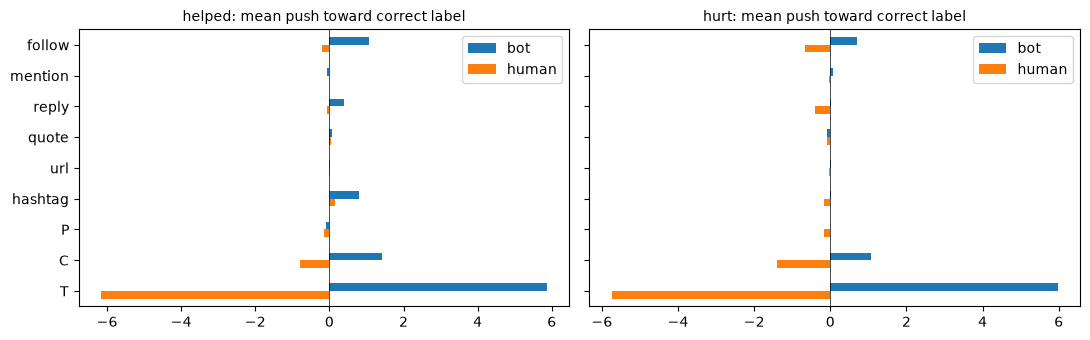

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (g, m) in zip(ax, [("helped", helped), ("hurt", hurt)]):
    sub = pd.DataFrame({lab: truth[m & lm][RELATIONS + ["P", "C", "T"]].mean() for lab, lm in [("bot", yv == 1), ("human", yv == 0)]})
    sub.plot.barh(ax=a); a.axvline(0, color="k", lw=0.5); a.set_title(f"{g}: mean push toward correct label", fontsize=10)
ax[0].invert_yaxis(); plt.tight_layout(); plt.show()

In [12]:
# Per-account table (ids, labels, scores, contributions) for follow-up work. Saved to data/ (gitignored): it holds
# MGTAB labels per account, and MGTAB data is never pushed.
out = pd.DataFrame({"account": val, "bot": yv, "group": D["group"].values,
                    **{f"score_{k}": m[1] for k, m in models.items()},
                    **{f"right_{k}": right[k] for k in models}})
out = pd.concat([out, contrib.add_prefix("contrib_"), D[RELATIONS].add_prefix("degree_").reset_index(drop=True)], axis=1)
out.to_csv("data/errors_val_accounts.csv", index=False)
out.shape

(1530, 25)

## Findings (validation, one split)

Fusion fixes 52 content-only errors and makes 28 new ones (net +24 of 1,530). Setting the G terms to their average
shows the graph decides 33 of the fixes and 18 of the new errors (net +15). The rest come from fusion's other weights
and threshold (its C is 0.1, content-only's is 10).

1. **The graph mainly catches quiet bots that content misses.** G decides 25 of the 28 fixed bots. These bots are
   sparse: median follow degree 5 (other bots 8), 68% have no mention edge (other bots 29%), 93% no reply or quote,
   57% no url edge. Their push toward bot comes from follow (+1.07 logit), hashtag (+0.80) and reply (+0.40).
   With so many zero degrees, much of the signal is the *absence* of interaction, not the neighbours.
2. **The same shortcut hurts quiet humans.** G decides 17 of the 18 humans that fusion now calls bots. They look like
   the bots in point 1: median follow degree 16 (other humans 27), 94% no reply edge (other humans 55%), none has a
   quote edge (other humans 39%). Follow (−0.65) and reply (−0.39) push them toward bot. "Low activity = bot" is
   right more often than wrong (25 fixed bots vs 17 broken humans), but it is the main source of graph noise.
3. **Graph-fixed humans are rarer.** Only 8 of the 24 fixed humans are due to G; the other 16 come from the change in
   content weights and threshold, not from the network.
4. **Follow and hashtag do most of the per-account work.** In the fixed group, the strongest single relation toward
   the right label is hashtag for 25 accounts and follow for 19; in the broken group, follow is the strongest push
   toward the wrong label for 14 of 28. This matches the relation ablation (`relations.ipynb`).
5. **For the RGCN:** (a) many accounts have no mention, reply or quote edges, so message passing gives them nothing;
   keep a self/root weight and feed each account's own degree features (G) as input, or the RGCN loses the signal
   that helped most. (b) Give zero degree its own signal per relation (for example an "isolated in this relation"
   flag), so the model can learn when absence matters. (c) Use the 18 broken quiet humans as a check set: neighbour
   information should help tell them apart from quiet bots, and the RGCN should break fewer of them than fusion-LR.

Caveats: small groups (52 and 28 accounts), one split; LR contributions are linear and the G columns are correlated,
so per-relation shares are indicative. Test set not used.